# EN4554 Assignment 2: CNN

- **Name:** Waduge S.S. 
- **Index:** 220673K
- **GitHub:** https://github.com/Platinum-Saber/EN4554-Assignment_02.git

In [1]:
import copy
import hashlib
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 4554
MODE = "full"
RUN_TASK4 = True
ALLOW_FINAL_TEST = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
EXPERIMENT_VERSION = "wsl-gpu-v2-batched-data"
DATA_DIR = Path("data")
OUT = Path("results/full_gpu")
OUT.mkdir(parents=True, exist_ok=True)
BATCH_SIZE = 128
NUM_WORKERS = 0
EPOCHS = {"mlp": 10, "optimizers": 15, "regularization": 25, "depth": 30, "final": 20}
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True})


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything()


def table(rows):
    if not rows:
        return
    fmt = lambda v: f"{v:.6g}" if isinstance(v, float) else str(v)
    keys = list(rows[0])
    display(Markdown("| " + " | ".join(keys) + " |\n| " + " | ".join(["---"] * len(keys)) + " |\n" +
                     "\n".join("| " + " | ".join(fmt(r[k]) for k in keys) + " |" for r in rows)))


def save_figure(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()


In [ ]:
# Only the official TRAINING dataset is loaded here.
raw_train = datasets.CIFAR10(DATA_DIR, train=True, download=True)
split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(raw_train), generator=split_generator).numpy()
train_indices, val_indices = permutation[:45000], permutation[45000:]
assert len(train_indices) == 45000 and len(val_indices) == 5000
assert not set(train_indices) & set(val_indices)

# Streaming float64 sums avoid a large temporary 45k-image float array.
channel_sum = np.zeros(3, dtype=np.float64)
channel_square_sum = np.zeros(3, dtype=np.float64)
pixels = 0
for start in range(0, len(train_indices), 500):
    chunk = raw_train.data[train_indices[start:start + 500]].astype(np.float64) / 255
    channel_sum += chunk.sum(axis=(0, 1, 2))
    channel_square_sum += (chunk * chunk).sum(axis=(0, 1, 2))
    pixels += np.prod(chunk.shape[:3])
MEAN = channel_sum / pixels
STD = np.sqrt(np.maximum(channel_square_sum / pixels - MEAN ** 2, 1e-12))
print("Training-only channel mean:", MEAN, "std:", STD)
np.savez(OUT / "split_and_normalization.npz", train=train_indices, validation=val_indices,
         mean=MEAN, std=STD)

targets = np.asarray(raw_train.targets)
subset_rng = np.random.default_rng(SEED)
regularization_indices = np.concatenate([
    subset_rng.choice(train_indices[targets[train_indices] == c], 500, replace=False)
    for c in range(10)
])
subset_rng.shuffle(regularization_indices)
assert len(regularization_indices) == 5000
assert set(regularization_indices) <= set(train_indices)


class Cutout:
    """Mask a square of a normalized image: zero means the training-channel mean."""
    def __init__(self, length=8):
        self.length = length

    def __call__(self, image):
        image = image.clone()
        h, w = image.shape[-2:]
        cy, cx = torch.randint(h, ()).item(), torch.randint(w, ()).item()
        y0, x0 = cy - self.length // 2, cx - self.length // 2
        image[:, max(0, y0):min(h, y0 + self.length),
              max(0, x0):min(w, x0 + self.length)] = 0
        return image


def make_transform(augment=False, cutout=False):
    ops = [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()] if augment else []
    ops += [transforms.ToTensor(), transforms.Normalize(MEAN.tolist(), STD.tolist())]
    if cutout:
        ops.append(Cutout(8))
    return transforms.Compose(ops)


class CIFARView(torch.utils.data.Dataset):
    # Share the raw training array, rather than reload 150 MB for every trial.
    def __init__(self, indices, transform):
        self.indices, self.transform = np.asarray(indices), transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, label = raw_train[int(self.indices[index])]
        return self.transform(image), label



# Cache only the official training archive on CUDA as uint8 (~147 MiB).
# Raw data remain unnormalized until batch selection; statistics above use train-only pixels.
CUDA_IMAGES = torch.from_numpy(raw_train.data).to(DEVICE)
CUDA_LABELS = torch.tensor(raw_train.targets, device=DEVICE, dtype=torch.long)
CUDA_MEAN = torch.tensor(MEAN, device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)
CUDA_STD = torch.tensor(STD, device=DEVICE, dtype=torch.float32).view(1, 3, 1, 1)


class CUDABatches:
    """GPU batches with custom crop, flip, and cutout; no per-image Python transforms."""
    def __init__(self, indices, shuffle=False, augment=False, cutout=False, seed=SEED):
        self.indices = torch.as_tensor(indices, device=DEVICE, dtype=torch.long)
        self.dataset = CIFARView(indices, make_transform())  # Introspection/length only.
        self.generator = torch.Generator().manual_seed(seed)
        self.shuffle, self.augment, self.cutout = shuffle, augment, cutout

    def __len__(self):
        return math.ceil(len(self.dataset) / BATCH_SIZE)

    def __iter__(self):
        size = len(self.dataset)
        order = (torch.randperm(size, generator=self.generator) if self.shuffle else torch.arange(size)).to(DEVICE)
        for start in range(0, size, BATCH_SIZE):
            ids = self.indices[order[start:start + BATCH_SIZE]]
            x = CUDA_IMAGES[ids].permute(0, 3, 1, 2).float().div_(255.)
            batch = len(ids)
            if self.augment:
                # torchvision's crop uses black padding BEFORE normalization.
                padded = F.pad(x, (4, 4, 4, 4)).permute(0, 2, 3, 1)
                row0 = torch.randint(9, (batch, 1, 1), device=DEVICE)
                col0 = torch.randint(9, (batch, 1, 1), device=DEVICE)
                rows = row0 + torch.arange(32, device=DEVICE).view(1, 32, 1)
                cols = col0 + torch.arange(32, device=DEVICE).view(1, 1, 32)
                x = padded[torch.arange(batch, device=DEVICE)[:, None, None], rows, cols].permute(0, 3, 1, 2)
                flip = torch.rand(batch, 1, 1, 1, device=DEVICE) < .5
                x = torch.where(flip, x.flip(-1), x)
            x = (x - CUDA_MEAN) / CUDA_STD
            if self.cutout:
                # Per-image centre, 8x8 square clipped at image boundaries; zero is channel mean.
                cy = torch.randint(32, (batch, 1, 1), device=DEVICE)
                cx = torch.randint(32, (batch, 1, 1), device=DEVICE)
                rows = torch.arange(32, device=DEVICE).view(1, 32, 1)
                cols = torch.arange(32, device=DEVICE).view(1, 1, 32)
                mask = (rows >= cy - 4) & (rows < cy + 4) & (cols >= cx - 4) & (cols < cx + 4)
                x = x.masked_fill(mask[:, None], 0.)
            yield x.contiguous(), CUDA_LABELS[ids]


def loaders(indices=None, augment=False, cutout=False, seed=SEED):
    chosen = train_indices if indices is None else np.asarray(indices)
    validation = val_indices
    if MODE == "smoke":
        chosen, validation = chosen[:256], validation[:256]
    return (CUDABatches(chosen, True, augment, cutout, seed),
            CUDABatches(chosen), CUDABatches(validation))


# Check the new clean preprocessing against the original torchvision pipeline.
check_indices = train_indices[:16]
fast_images, fast_labels = next(iter(CUDABatches(check_indices)))
reference_images = torch.stack([make_transform()(raw_train[int(i)][0]) for i in check_indices]).to(DEVICE)
assert torch.allclose(fast_images, reference_images, atol=1e-6, rtol=1e-6)
assert torch.equal(fast_labels, torch.tensor(targets[check_indices], device=DEVICE))
augmented_images, _ = next(iter(CUDABatches(check_indices, augment=True, cutout=True)))
assert augmented_images.shape == (16, 3, 32, 32) and torch.isfinite(augmented_images).all()
print("Batched CUDA preprocessing matches torchvision's clean normalization.")


table([{"split": "train", "images": len(train_indices)},
       {"split": "validation", "images": len(val_indices)},
       {"split": "Task 3(a) train", "images": len(regularization_indices)}])


Training-only channel mean: [0.49196089 0.4825111  0.44676395] std: [0.24700856 0.24348106 0.26154144]


Batched CUDA preprocessing matches torchvision's clean normalization.


| split | images |
| --- | --- |
| train | 45000 |
| validation | 5000 |
| Task 3(a) train | 5000 |

## Task 1: Backpropagation
### (a) Manual layers
Linear: $Z=XW+b$, $dX=dZW^T$, $dW=X^TdZ$, $db=\sum_i dZ_i$. ReLU passes gradient where input $>0$. Softmax cross-entropy: $dZ=(P-\text{onehot}(y))/B$ (row-max shift for stability). No autograd is used.


In [2]:
class ManualLinear:
    def __init__(self, in_features, out_features, device="cpu", dtype=torch.float32):
        self.W = torch.randn(in_features, out_features, device=device, dtype=dtype) * math.sqrt(2 / in_features)
        self.b = torch.zeros(out_features, device=device, dtype=dtype)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, grad):
        self.dW = self.x.T @ grad
        self.db = grad.sum(0)
        return grad @ self.W.T


class ManualReLU:
    def forward(self, x):
        self.mask = x > 0
        return x.clamp_min(0)

    def backward(self, grad):
        return grad * self.mask


class ManualSigmoid:
    def forward(self, x):
        self.output = torch.sigmoid(x)
        return self.output

    def backward(self, grad):
        return grad * self.output * (1 - self.output)


class ManualCrossEntropy:
    def forward(self, logits, labels):
        shifted = logits - logits.max(dim=1, keepdim=True).values
        log_probs = shifted - shifted.exp().sum(1, keepdim=True).log()
        self.probabilities = log_probs.exp()
        self.labels = labels
        return -log_probs[torch.arange(len(labels), device=logits.device), labels].mean()

    def backward(self):
        grad = self.probabilities.clone()
        grad[torch.arange(len(self.labels), device=grad.device), self.labels] -= 1
        return grad / len(self.labels)


class ManualMLP:
    def __init__(self, sizes, activation="relu", device="cpu", dtype=torch.float32):
        self.layers = []
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(ManualLinear(a, b, device, dtype))
            if i < len(sizes) - 2:
                self.layers.append(ManualReLU() if activation == "relu" else ManualSigmoid())

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, grad):
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
        return grad

    def parameters_and_gradients(self):
        for layer in self.layers:
            if isinstance(layer, ManualLinear):
                yield layer.W, layer.dW
                yield layer.b, layer.db

    def step(self, lr):
        for parameter, grad in self.parameters_and_gradients():
            parameter.add_(grad, alpha=-lr)


### (b) Gradient check
Relative error $\|g-g_{ref}\|/(\|g\|+\|g_{ref}\|)$ against autograd and centred differences ($h=10^{-6}$, float64).


In [ ]:
def relative_error(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-12)).item()


def gradient_checks():
    seed_everything()
    model = ManualMLP([4, 5, 3], dtype=torch.float64)
    x = torch.randn(6, 4, dtype=torch.float64)
    y = torch.tensor([0, 1, 2, 0, 2, 1])
    loss_fn = ManualCrossEntropy()
    loss_fn.forward(model.forward(x), y)
    dx = model.backward(loss_fn.backward())
    manual = [(p, g.clone()) for p, g in model.parameters_and_gradients()]
    reference_params = [p.clone().requires_grad_() for p, _ in manual]
    xr = x.clone().requires_grad_()
    z = F.relu(xr @ reference_params[0] + reference_params[1])
    reference_loss = F.cross_entropy(z @ reference_params[2] + reference_params[3], y)
    reference_loss.backward()

    def scalar_loss():
        return loss_fn.forward(model.forward(x), y).item()

    rows = []
    names = ["layer1.W", "layer1.b", "layer2.W", "layer2.b", "input"]
    items = list(zip(manual, reference_params)) + [((x, dx.clone()), xr)]
    for name, ((parameter, grad), ref) in zip(names, items):
        numerical = torch.zeros_like(parameter)
        for j in range(parameter.numel()):
            flat = parameter.view(-1)
            original = flat[j].item()
            flat[j] = original + 1e-6
            plus = scalar_loss()
            flat[j] = original - 1e-6
            minus = scalar_loss()
            flat[j] = original
            numerical.view(-1)[j] = (plus - minus) / 2e-6
        ag_ok = torch.allclose(grad, ref.grad, rtol=1e-8, atol=1e-10)
        fd_ok = torch.allclose(grad, numerical, rtol=1e-5, atol=1e-7)
        assert ag_ok and fd_ok, f"Gradient mismatch: {name}"
        rows.append({"gradient": name, "autograd relative error": relative_error(grad, ref.grad),
                     "finite-difference relative error": relative_error(grad, numerical),
                     "autograd allclose": ag_ok, "finite-difference allclose": fd_ok})
    return rows


gradient_rows = gradient_checks()
table(gradient_rows)
print("All manual gradients agree with both independent references.")


| gradient | autograd relative error | finite-difference relative error | autograd allclose | finite-difference allclose |
| --- | --- | --- | --- | --- |
| layer1.W | 5.66783e-17 | 2.13993e-10 | True | True |
| layer1.b | 3.37887e-17 | 1.0431e-10 | True | True |
| layer2.W | 2.36681e-17 | 2.00749e-10 | True | True |
| layer2.b | 1.13563e-16 | 4.35747e-10 | True | True |
| input | 9.77031e-17 | 1.84922e-10 | True | True |

All manual gradients agree with both independent references.


**Interpretation.** Errors vs autograd are ~$10^{-17}$ (machine precision) and vs finite differences ~$10^{-10}$ (truncation/rounding of the numerical estimate); all `allclose` checks pass, so the backward pass is correct.

### (c) Train the manual MLP with SGD


MLP 1: loss=1.8365, val_acc=40.160%


MLP 2: loss=1.5889, val_acc=42.680%


MLP 3: loss=1.4931, val_acc=44.860%


MLP 4: loss=1.4236, val_acc=46.000%


MLP 5: loss=1.3671, val_acc=46.980%


MLP 6: loss=1.3194, val_acc=47.940%


MLP 7: loss=1.2758, val_acc=48.420%


MLP 8: loss=1.2375, val_acc=48.960%


MLP 9: loss=1.2011, val_acc=48.960%


MLP 10: loss=1.1683, val_acc=49.060%


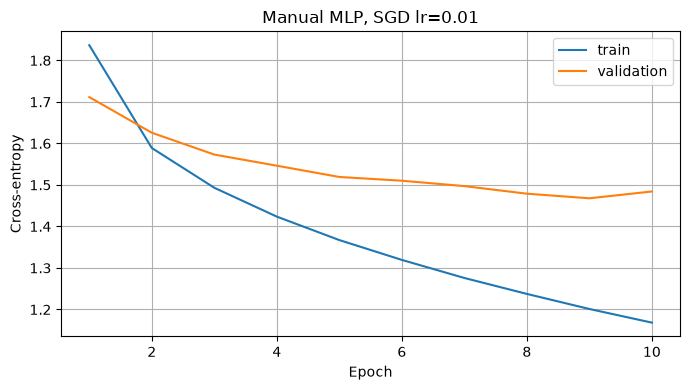

Best MLP validation accuracy: **49.06%** at epoch 10.

In [ ]:
@torch.no_grad()
def manual_metrics(model, loader):
    total_loss, correct, count = 0., 0, 0
    loss_fn = ManualCrossEntropy()
    for x, y in loader:
        x, y = x.to(DEVICE).flatten(1), y.to(DEVICE)
        logits = model.forward(x)
        total_loss += loss_fn.forward(logits, y).item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        count += len(y)
    return total_loss / count, correct / count


@torch.no_grad()
def train_manual_mlp():
    seed_everything()
    train_loader, clean_loader, validation_loader = loaders()
    model = ManualMLP([3072, 256, 128, 10], device=DEVICE)
    loss_fn = ManualCrossEntropy()
    history = []
    for epoch in range(EPOCHS["mlp"]):
        loss_sum, count = 0., 0
        for x, y in train_loader:
            x, y = x.to(DEVICE).flatten(1), y.to(DEVICE)
            loss = loss_fn.forward(model.forward(x), y)
            model.backward(loss_fn.backward())
            model.step(lr=0.01)
            loss_sum += loss.item() * len(y)
            count += len(y)
        val_loss, val_acc = manual_metrics(model, validation_loader)
        history.append({"epoch": epoch + 1, "train_loss": loss_sum / count,
                        "val_loss": val_loss, "val_acc": val_acc})
        print(f"MLP {epoch + 1}: loss={loss_sum / count:.4f}, val_acc={val_acc:.3%}")
    return model, history


manual_model, mlp_history = train_manual_mlp()
plt.plot([r["epoch"] for r in mlp_history], [r["train_loss"] for r in mlp_history], label="train")
plt.plot([r["epoch"] for r in mlp_history], [r["val_loss"] for r in mlp_history], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy"); plt.title("Manual MLP, SGD lr=0.01"); plt.legend()
save_figure("task1_mlp_loss")
best_mlp = max(mlp_history, key=lambda r: r["val_acc"])
display(Markdown(f"Best MLP validation accuracy: **{best_mlp['val_acc']:.2%}** at epoch {best_mlp['epoch']}. "
                 "Compare the loss trends: falling training loss with rising validation loss suggests overfitting; "
                 "if both remain high, inspect optimization and model capacity."))


**Interpretation (c).** Training loss falls steadily 1.84 → 1.17 and validation accuracy reaches 49.1%, with gains slowing after epoch 7 — typical ceiling for an MLP on raw pixels, which ignores spatial structure.

### (d) Gradient flow in a 10-layer MLP (same He init for both)


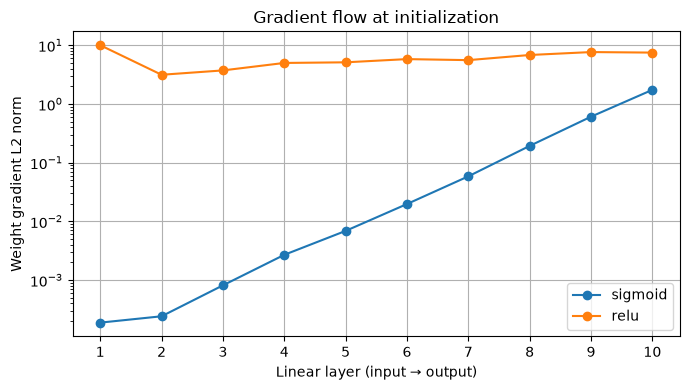

sigmoid: first/last gradient norm = 1.081e-04
relu: first/last gradient norm = 1.337e+00


In [ ]:
seed_everything()
grad_x, grad_y = next(iter(loaders()[1]))
gradient_norms = {}
for activation in ["sigmoid", "relu"]:
    seed_everything()
    deep = ManualMLP([3072] + [128] * 9 + [10], activation, device=DEVICE)
    criterion = ManualCrossEntropy()
    criterion.forward(deep.forward(grad_x.to(DEVICE).flatten(1)), grad_y.to(DEVICE))
    deep.backward(criterion.backward())
    gradient_norms[activation] = [layer.dW.norm().item() for layer in deep.layers
                                  if isinstance(layer, ManualLinear)]
    plt.semilogy(range(1, 11), np.maximum(gradient_norms[activation], 1e-20), "o-", label=activation)
plt.xlabel("Linear layer (input → output)"); plt.ylabel("Weight gradient L2 norm")
plt.title("Gradient flow at initialization"); plt.xticks(range(1, 11)); plt.legend()
save_figure("task1_gradient_flow")
for name, norms in gradient_norms.items():
    print(f"{name}: first/last gradient norm = {norms[0] / max(norms[-1], 1e-20):.3e}")


**Interpretation.** With sigmoid the first-layer gradient is ~$10^{-4}$ of the last layer's: $\sigma'\le 1/4$, so the backward signal shrinks geometrically (vanishing gradients). With ReLU (derivative 1 when active) plus He init the norms stay at the same order across layers (ratio ≈ 1.3).

## Task 2: Optimizers
### (a) Implementations
Momentum: $v_t=\mu v_{t-1}+g_t$, $\theta_t=\theta_{t-1}-\eta v_t$. Adam: $\hat m_t=m_t/(1-\beta_1^t)$, $\hat v_t=v_t/(1-\beta_2^t)$, $\theta_t=\theta_{t-1}-\eta\hat m_t/(\sqrt{\hat v_t}+\epsilon)$. Weight decay is coupled L2 (as in `torch.optim`).


In [ ]:
class MomentumSGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9, weight_decay=0.):
        if lr < 0 or not 0 <= momentum < 1 or weight_decay < 0:
            raise ValueError("Invalid SGD hyperparameters")
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                if p.grad.is_sparse:
                    raise RuntimeError("Sparse gradients are unsupported")
                grad = p.grad
                if group["weight_decay"]:
                    grad = grad.add(p, alpha=group["weight_decay"])
                if group["momentum"]:
                    state = self.state[p]
                    if "momentum_buffer" not in state:
                        state["momentum_buffer"] = grad.clone()
                    else:
                        state["momentum_buffer"].mul_(group["momentum"]).add_(grad)
                    grad = state["momentum_buffer"]
                p.add_(grad, alpha=-group["lr"])
        return loss


class ManualAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=0.001, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.):
        if lr < 0 or eps < 0 or weight_decay < 0 or not all(0 <= b < 1 for b in betas):
            raise ValueError("Invalid Adam hyperparameters")
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            b1, b2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                if p.grad.is_sparse:
                    raise RuntimeError("Sparse gradients are unsupported")
                grad = p.grad
                if group["weight_decay"]:
                    grad = grad.add(p, alpha=group["weight_decay"])
                state = self.state[p]
                if not state:
                    state.update(step=0, exp_avg=torch.zeros_like(p), exp_avg_sq=torch.zeros_like(p))
                state["step"] += 1
                state["exp_avg"].mul_(b1).add_(grad, alpha=1 - b1)
                state["exp_avg_sq"].mul_(b2).addcmul_(grad, grad, value=1 - b2)
                t = state["step"]
                m_hat = state["exp_avg"] / (1 - b1 ** t)
                v_hat = state["exp_avg_sq"] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group["eps"]), value=-group["lr"])
        return loss


def optimizer_checks():
    rows = []
    pairs = [("SGD", MomentumSGD, torch.optim.SGD, {"lr": .03, "momentum": 0.}),
             ("momentum", MomentumSGD, torch.optim.SGD, {"lr": .03, "momentum": .9}),
             ("Adam", ManualAdam, torch.optim.Adam, {"lr": .003, "betas": (.8, .95)})]
    for name, custom, builtin, kwargs in pairs:
        for decay in [0., .01]:
            seed_everything()
            a = [nn.Parameter(torch.randn(3, 4, dtype=torch.float64)),
                 nn.Parameter(torch.randn(4, dtype=torch.float64))]
            b = [nn.Parameter(p.detach().clone()) for p in a]
            ours, theirs = custom(a, weight_decay=decay, **kwargs), builtin(b, weight_decay=decay, **kwargs)
            max_error = 0.
            for t in range(12):
                for j, (p, q) in enumerate(zip(a, b)):
                    # Check absent gradients and a zero-gradient update as well as random gradients.
                    grad = None if t == 4 and j == 0 else (torch.zeros_like(p) if t == 7 else torch.randn_like(p))
                    p.grad = grad
                    q.grad = None if grad is None else grad.clone()
                ours.step(); theirs.step()
                for p, q in zip(a, b):
                    max_error = max(max_error, (p - q).abs().max().item())
                    assert torch.allclose(p, q, atol=1e-11, rtol=1e-9)
            rows.append({"optimizer": name, "weight decay": decay,
                         "max absolute parameter error": max_error, "allclose every step": True})
    return rows


table(optimizer_checks())


| optimizer | weight decay | max absolute parameter error | allclose every step |
| --- | --- | --- | --- |
| SGD | 0 | 0 | True |
| SGD | 0.01 | 0 | True |
| momentum | 0 | 0 | True |
| momentum | 0.01 | 0 | True |
| Adam | 0 | 5.55112e-17 | True |
| Adam | 0.01 | 0 | True |

**Interpretation.** Parameters match `torch.optim.SGD`/`Adam` at every step (max error ≤ $6\times10^{-17}$), with and without weight decay.

### (b) Trajectories on $f(x,y)=\tfrac12(x^2+50y^2)$
Hessian eigenvalues 1 and 50 (condition number 50).


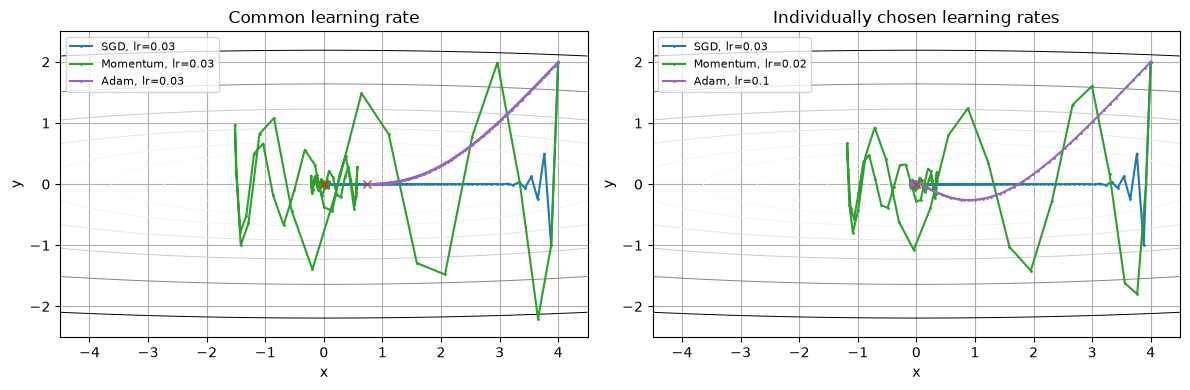

| setting | optimizer | lr | final f |
| --- | --- | --- | --- |
| Common learning rate | SGD | 0.03 | 0.000860221 |
| Common learning rate | Momentum | 0.03 | 2.1753e-05 |
| Common learning rate | Adam | 0.03 | 0.273766 |
| Individually chosen learning rates | SGD | 0.03 | 0.000860221 |
| Individually chosen learning rates | Momentum | 0.02 | 8.18325e-07 |
| Individually chosen learning rates | Adam | 0.1 | 8.54542e-07 |

In [ ]:
def make_optimizer(name, params, lr, weight_decay=0.):
    if name == "SGD":
        return MomentumSGD(params, lr=lr, momentum=0., weight_decay=weight_decay)
    if name == "Momentum":
        return MomentumSGD(params, lr=lr, momentum=.9, weight_decay=weight_decay)
    if name == "Adam":
        return ManualAdam(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(name)


def quadratic_path(name, lr, steps=150):
    p = nn.Parameter(torch.tensor([4., 2.], dtype=torch.float64))
    optimizer = make_optimizer(name, [p], lr)
    path = [p.detach().numpy().copy()]
    for _ in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = .5 * (p[0] ** 2 + 50 * p[1] ** 2)
        loss.backward(); optimizer.step()
        path.append(p.detach().numpy().copy())
    return np.stack(path)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
grid_x, grid_y = np.meshgrid(np.linspace(-4.5, 4.5, 220), np.linspace(-2.5, 2.5, 220))
quadratic_rows = []
for ax, title, rates in zip(axes, ["Common learning rate", "Individually chosen learning rates"],
                            [{"SGD": .03, "Momentum": .03, "Adam": .03},
                             {"SGD": .03, "Momentum": .02, "Adam": .1}]):
    ax.contour(grid_x, grid_y, .5 * (grid_x ** 2 + 50 * grid_y ** 2),
               levels=np.geomspace(.02, 120, 16), cmap="Greys", linewidths=.7)
    for name, lr in rates.items():
        path = quadratic_path(name, lr)
        ax.plot(path[:, 0], path[:, 1], ".-", markersize=2, label=f"{name}, lr={lr}")
        ax.plot(*path[-1], "x")
        quadratic_rows.append({"setting": title, "optimizer": name, "lr": lr,
                               "final f": float(.5 * (path[-1, 0] ** 2 + 50 * path[-1, 1] ** 2))})
    ax.set(xlabel="x", ylabel="y", title=title); ax.legend(fontsize=8)
save_figure("task2_quadratic")
table(quadratic_rows)


**Interpretation.** SGD's step is limited by the steep $y$ direction ($\eta<2/50$), so it zig-zags in $y$ and crawls along $x$ (final $f\approx 9\times10^{-4}$). Momentum averages out the oscillation and accumulates speed along $x$, overshooting but converging much faster ($2\times10^{-5}$). Adam normalizes each coordinate by its gradient magnitude, so it moves almost diagonally regardless of curvature; at lr 0.03 it is still far ($0.27$) because its step size ≈ lr per coordinate, but at lr 0.1 it reaches $9\times10^{-7}$.

### Shared CNN training utilities


In [ ]:
def kaiming_init(module):
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        nn.init.kaiming_normal_(module.weight, mode="fan_in", nonlinearity="relu")
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.ones_(module.weight); nn.init.zeros_(module.bias)


class SmallCNN(nn.Module):
    def __init__(self, dropout=0.):
        super().__init__()
        layers = []
        cin = 3
        for cout in [32, 64, 128]:
            layers += [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
                       nn.ReLU(), nn.MaxPool2d(2), nn.Dropout2d(dropout)]
            cin = cout
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(128, 10)
        self.apply(kaiming_init)

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)).flatten(1))


def mixup_batch(x, y, alpha=.4):
    if alpha <= 0:
        return x, y, y, 1.
    lam = float(np.random.beta(alpha, alpha))
    order = torch.randperm(len(y), device=y.device)
    return lam * x + (1 - lam) * x[order], y, y[order], lam


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0., 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(1) == y).sum().item()
        total += len(y)
    return {"loss": loss_sum / total, "acc": correct / total}



def fit_run(name, factory, optimizer_name, lr, epochs, indices=None,
            weight_decay=0., augment=False, cutout=False, mixup=False):
    seed_everything()
    train_loader, clean_loader, val_loader = loaders(indices, augment, cutout)
    model = factory().to(DEVICE)
    optimizer = make_optimizer(optimizer_name, model.parameters(), lr, weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    selected_indices = train_indices if indices is None else np.asarray(indices)
    config = dict(name=name, optimizer=optimizer_name, lr=lr, requested_epochs=epochs,
                  weight_decay=weight_decay, augment=augment, cutout=cutout, mixup=mixup,
                  train_size=len(train_loader.dataset), val_size=len(val_loader.dataset),
                  seed=SEED, mode=MODE, amp=USE_AMP, experiment_version=EXPERIMENT_VERSION,
                  architecture=repr(model), torch=str(torch.__version__),
                  data_indices_sha256=hashlib.sha256(selected_indices.tobytes()).hexdigest())
    result_path = OUT / f"{name}.json"
    checkpoint = OUT / f"{name}.pt"
    resume_path = OUT / f"{name}.resume.pt"
    if result_path.exists() and checkpoint.exists():
        cached = json.loads(result_path.read_text(encoding="utf-8"))
        if cached.get("config") == config and cached.get("completed_epochs") == epochs and not cached["failed"]:
            print(f"{name}: using completed run ({epochs} epochs)", flush=True)
            return cached
    history, best_acc, best_state, best_epoch = [], -1., None, None
    elapsed = 0.
    if resume_path.exists():
        # This is our own local checkpoint, including Python/NumPy RNG state.
        saved = torch.load(resume_path, map_location="cpu", weights_only=False)
        if saved["config"] != config:
            raise RuntimeError(f"Resume configuration mismatch for {name}; use a new experiment name")
        model.load_state_dict(saved["model"])
        optimizer.load_state_dict(saved["optimizer"])
        scaler.load_state_dict(saved["scaler"])
        history, best_acc = saved["history"], saved["best_acc"]
        best_state, best_epoch, elapsed = saved["best_state"], saved["best_epoch"], saved["seconds"]
        random.setstate(saved["python_rng"])
        np.random.set_state(saved["numpy_rng"])
        torch.set_rng_state(saved["torch_rng"])
        torch.cuda.set_rng_state_all(saved["cuda_rng"])
        train_loader.generator.set_state(saved["loader_rng"])
        print(f"{name}: resuming after epoch {len(history)}", flush=True)
    failed = False
    started = time.perf_counter()
    for epoch in range(len(history) + 1, epochs + 1):
        # Epoch-keyed augmentations are reproducible after resuming the kernel.
        # Batched CUDA transforms use these epoch-specific seeds.
        seed_everything(SEED + epoch)
        model.train()
        total_loss, total = 0., 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                if mixup:
                    x, ya, yb, lam = mixup_batch(x, y)
                    logits = model(x)
                    loss = lam * F.cross_entropy(logits, ya) + (1 - lam) * F.cross_entropy(logits, yb)
                else:
                    loss = F.cross_entropy(model(x), y)
            if not torch.isfinite(loss):
                failed = True
                break
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item() * len(y)
            total += len(y)
        if failed:
            print(f"{name}: non-finite loss at epoch {epoch}; trial marked failed", flush=True)
            break
        train_metrics, val_metrics = evaluate(model, clean_loader), evaluate(model, val_loader)
        row = dict(epoch=epoch, train_loss=total_loss / total,
                   clean_train_loss=train_metrics["loss"], train_acc=train_metrics["acc"],
                   val_loss=val_metrics["loss"], val_acc=val_metrics["acc"])
        history.append(row)
        if row["val_acc"] > best_acc:
            best_acc, best_epoch = row["val_acc"], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        progress = dict(config=config, history=history, best_epoch=best_epoch,
                        best_val_acc=best_acc, failed=False,
                        seconds=elapsed + time.perf_counter() - started,
                        completed_epochs=len(history), checkpoint=str(checkpoint))
        result_path.write_text(json.dumps(progress, indent=2), encoding="utf-8")
        saved = dict(config=config, model=model.state_dict(), optimizer=optimizer.state_dict(),
                     scaler=scaler.state_dict(), history=history, best_acc=best_acc,
                     best_state=best_state, best_epoch=best_epoch, seconds=progress["seconds"],
                     python_rng=random.getstate(), numpy_rng=np.random.get_state(),
                     torch_rng=torch.get_rng_state(), cuda_rng=torch.cuda.get_rng_state_all(),
                     loader_rng=train_loader.generator.get_state())
        temporary = resume_path.with_suffix(".tmp")
        torch.save(saved, temporary)
        temporary.replace(resume_path)
        print(f"{name} {epoch}/{epochs}: loss={row['train_loss']:.4f}, "
              f"train={row['train_acc']:.2%}, val={row['val_acc']:.2%}, "
              f"elapsed={progress['seconds'] / 60:.1f}m", flush=True)
    result = dict(config=config, history=history, best_epoch=best_epoch,
                  best_val_acc=best_acc if not failed else -1., failed=failed,
                  seconds=elapsed + time.perf_counter() - started, completed_epochs=len(history),
                  checkpoint=str(checkpoint))
    if best_state is not None:
        torch.save(dict(state_dict=best_state, config=config, best_epoch=best_epoch,
                        mean=MEAN.tolist(), std=STD.tolist()), checkpoint)
    result_path.write_text(json.dumps(result, indent=2), encoding="utf-8")
    return result


def best_row(result):
    if result["failed"] or not result["history"]:
        return None
    return result["history"][result["best_epoch"] - 1]


def plot_histories(results, metric, title, filename):
    plt.figure(figsize=(8, 4))
    for name, result in results.items():
        if result["history"]:
            plt.plot([h["epoch"] for h in result["history"]],
                     [h[metric] for h in result["history"]], label=name)
    plt.xlabel("Epoch"); plt.ylabel(metric.replace("_", " ")); plt.title(title)
    plt.legend(fontsize=8); save_figure(filename)


### (c) Small CNN: three learning rates per optimizer (15 epochs, same init and data order)


task2_SGD_0.001 15/15: loss=1.6581, train=42.02%, val=42.28%, elapsed=0.9m


task2_SGD_0.01 15/15: loss=1.1570, train=60.36%, val=59.56%, elapsed=0.8m


task2_SGD_0.1 15/15: loss=0.6606, train=70.07%, val=65.34%, elapsed=0.9m


task2_Momentum_0.001 15/15: loss=1.1553, train=61.07%, val=60.18%, elapsed=0.9m


task2_Momentum_0.01 15/15: loss=0.6310, train=78.79%, val=71.90%, elapsed=0.9m


task2_Momentum_0.1 15/15: loss=0.3376, train=81.83%, val=71.82%, elapsed=0.9m


task2_Adam_0.0001 15/15: loss=1.0555, train=64.48%, val=62.84%, elapsed=1.1m


task2_Adam_0.001 15/15: loss=0.5579, train=79.82%, val=71.46%, elapsed=1.2m


task2_Adam_0.01 15/15: loss=0.2787, train=72.41%, val=64.14%, elapsed=1.2m


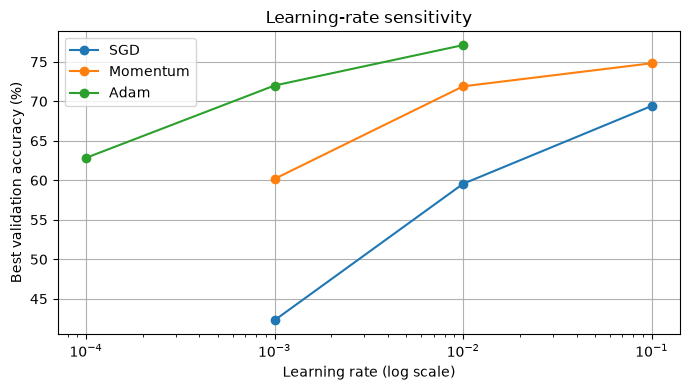

| optimizer | best lr | validation accuracy (%) | range across rates (pp) |
| --- | --- | --- | --- |
| SGD | 0.1 | 69.42 | 27.14 |
| Momentum | 0.1 | 74.82 | 14.64 |
| Adam | 0.01 | 77.12 | 14.28 |

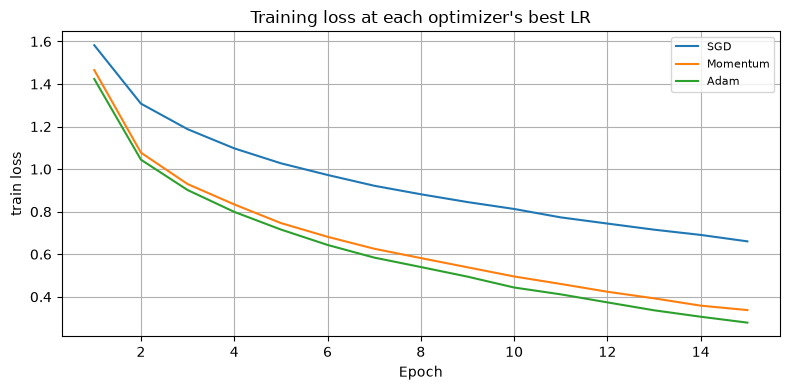

**SGD** selected lr=0.1, reaching 69.42% validation accuracy; the measured spread across successful rates is 27.14 percentage points.

**Momentum** selected lr=0.1, reaching 74.82% validation accuracy; the measured spread across successful rates is 14.64 percentage points.

**Adam** selected lr=0.01, reaching 77.12% validation accuracy; the measured spread across successful rates is 14.28 percentage points.

In [ ]:
LR_GRIDS = {"SGD": [.001, .01, .1], "Momentum": [.001, .01, .1], "Adam": [.0001, .001, .01]}
optimizer_runs = {}
for optimizer_name, rates in LR_GRIDS.items():
    for lr in rates:
        name = f"task2_{optimizer_name}_{lr:g}"
        optimizer_runs[(optimizer_name, lr)] = fit_run(
            name, SmallCNN, optimizer_name, lr, EPOCHS["optimizers"])

plt.figure()
for name, rates in LR_GRIDS.items():
    scores = [optimizer_runs[(name, lr)]["best_val_acc"] for lr in rates]
    plt.semilogx(rates, [np.nan if v < 0 else v * 100 for v in scores], "o-", label=name)
plt.xlabel("Learning rate (log scale)"); plt.ylabel("Best validation accuracy (%)")
plt.title("Learning-rate sensitivity"); plt.legend(); save_figure("task2_lr_sensitivity")

best_optimizer_runs = {}
optimizer_summary = []
for name, rates in LR_GRIDS.items():
    candidates = [optimizer_runs[(name, lr)] for lr in rates if not optimizer_runs[(name, lr)]["failed"]]
    assert candidates, f"All {name} trials failed; inspect loss before proceeding"
    best = max(candidates, key=lambda r: r["best_val_acc"])
    best_optimizer_runs[name] = best
    optimizer_summary.append({"optimizer": name, "best lr": best["config"]["lr"],
                              "validation accuracy (%)": 100 * best["best_val_acc"],
                              "range across rates (pp)": 100 * (max(r["best_val_acc"] for r in candidates) -
                                                                  min(r["best_val_acc"] for r in candidates))})
table(optimizer_summary)
plot_histories(best_optimizer_runs, "train_loss", "Training loss at each optimizer's best LR", "task2_best_losses")
for row in optimizer_summary:
    display(Markdown(f"**{row['optimizer']}** selected lr={row['best lr']:g}, reaching "
                     f"{row['validation accuracy (%)']:.2f}% validation accuracy; the measured "
                     f"spread across successful rates is {row['range across rates (pp)']:.2f} percentage points."))


**Discussion.** Best validation: Adam 77.1% (lr 0.01) > Momentum 74.8% (lr 0.1) > SGD 69.4% (lr 0.1). Plain SGD is most sensitive (27 pp spread across rates): at 0.001 it barely trains, and at 0.1 its validation accuracy fluctuates strongly between epochs. Momentum and Adam spread ~14 pp. Momentum at lr 0.001 behaves like SGD at 0.01, consistent with an effective rate $\eta/(1-\mu)$. Adam converges fastest in training loss, matching the quadratic experiment where per-coordinate scaling handled poor conditioning.

## Task 3: Regularization and residual connections
### (a) Regularization on 5k training images
Baseline vs weight decay ($5\times10^{-4}$), dropout (0.25), flip+crop, cutout (8 px), mixup ($\alpha=0.4$), all combined. Momentum SGD, lr 0.03, 25 epochs.


task3a_baseline 25/25: loss=0.6445, train=74.42%, val=55.82%, elapsed=0.2m


task3a_weight_decay 25/25: loss=0.6920, train=72.52%, val=56.14%, elapsed=0.2m


task3a_dropout 25/25: loss=1.5654, train=51.42%, val=48.80%, elapsed=0.2m


task3a_flip_crop 25/25: loss=1.1167, train=58.40%, val=55.50%, elapsed=0.2m


task3a_cutout 25/25: loss=0.8720, train=73.68%, val=58.38%, elapsed=0.2m


task3a_mixup 25/25: loss=1.2770, train=71.30%, val=58.02%, elapsed=0.2m


task3a_all_combined 25/25: loss=1.9493, train=38.62%, val=38.56%, elapsed=0.3m


| setting | selected epoch | clean train accuracy (%) | validation accuracy (%) | gap (percentage points) |
| --- | --- | --- | --- | --- |
| baseline | 20 | 72.48 | 55.94 | 16.54 |
| weight_decay | 20 | 73.34 | 56.74 | 16.6 |
| dropout | 25 | 51.42 | 48.8 | 2.62 |
| flip_crop | 16 | 57.9 | 56.08 | 1.82 |
| cutout | 25 | 73.68 | 58.38 | 15.3 |
| mixup | 19 | 69.24 | 58.72 | 10.52 |
| all_combined | 21 | 40.7 | 40 | 0.7 |

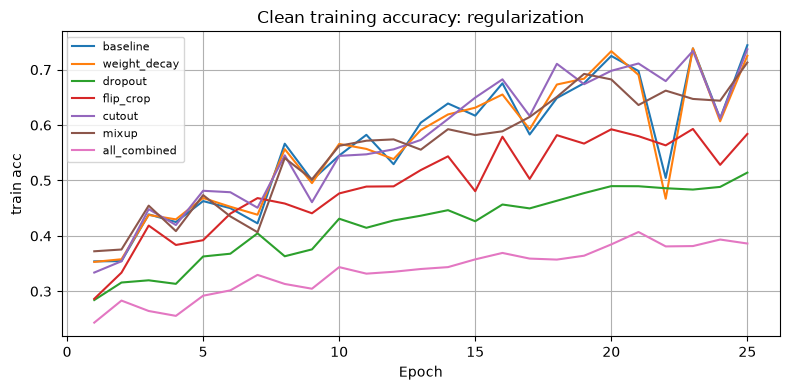

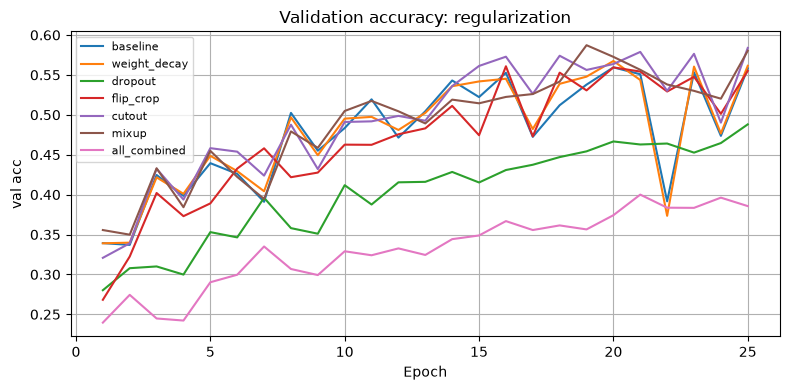

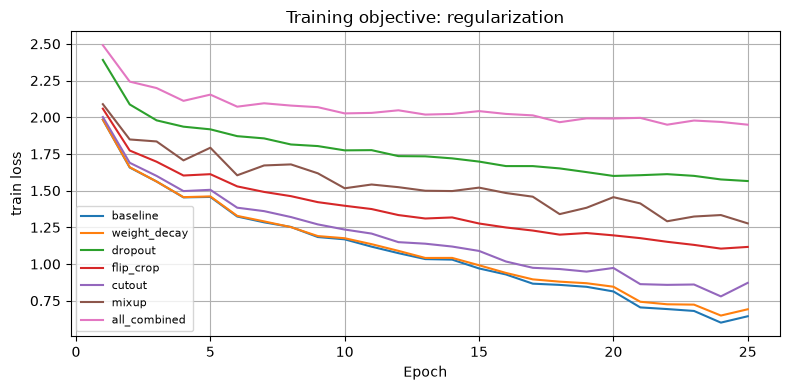

The highest measured validation accuracy is **mixup**, 58.72%, with a clean train–validation gap of 10.52 points at epoch 19.

In [ ]:
REGULARIZERS = {
    "baseline": {},
    "weight_decay": {"weight_decay": 5e-4},
    "dropout": {"dropout": .25},
    "flip_crop": {"augment": True},
    "cutout": {"cutout": True},
    "mixup": {"mixup": True},
    "all_combined": {"weight_decay": 5e-4, "dropout": .25, "augment": True, "cutout": True, "mixup": True},
}
regularization_runs = {}
for label, options in REGULARIZERS.items():
    kwargs = options.copy()
    dropout = kwargs.pop("dropout", 0.)
    regularization_runs[label] = fit_run(
        f"task3a_{label}", lambda p=dropout: SmallCNN(p), "Momentum", .03,
        EPOCHS["regularization"], indices=regularization_indices, **kwargs)

regularization_rows = []
for label, result in regularization_runs.items():
    row = best_row(result)
    if row:
        regularization_rows.append({"setting": label, "selected epoch": row["epoch"],
                                    "clean train accuracy (%)": 100 * row["train_acc"],
                                    "validation accuracy (%)": 100 * row["val_acc"],
                                    "gap (percentage points)": 100 * (row["train_acc"] - row["val_acc"])})
table(regularization_rows)
plot_histories(regularization_runs, "train_acc", "Clean training accuracy: regularization", "task3a_train_accuracy")
plot_histories(regularization_runs, "val_acc", "Validation accuracy: regularization", "task3a_validation_accuracy")
plot_histories(regularization_runs, "train_loss", "Training objective: regularization", "task3a_training_loss")
if regularization_rows:
    winner = max(regularization_rows, key=lambda r: r["validation accuracy (%)"])
    display(Markdown(f"The highest measured validation accuracy is **{winner['setting']}**, "
                     f"{winner['validation accuracy (%)']:.2f}%, with a clean train–validation gap "
                     f"of {winner['gap (percentage points)']:.2f} points at epoch {winner['selected epoch']}."))


**Discussion.** The baseline overfits (72.5% train vs 55.9% val, 16.5 pp gap). Weight decay alone has little effect at this budget. Flip+crop cuts the gap to 1.8 pp with similar validation accuracy, so it removes memorization but is still undertrained after 25 epochs. Cutout (58.4%) and mixup (58.7%, best) improve validation accuracy, and mixup also halves the gap. Dropout and especially all combined (40.0% val, 0.7 pp gap) **underfit**: the gap is small because train accuracy collapses, not because generalization improves. Stacking regularizers on a small model with a short budget over-regularizes.

### (b) Plain vs residual networks, depth $6n+2$ = 8, 20, 56
3×3 stem, three stages (16/32/64), $n$ blocks per stage, GAP, linear classifier, BN, Kaiming init. Parameter-free option-A shortcuts (stride + zero-pad), so the only difference is the shortcut addition.


In [ ]:
class CIFARBlock(nn.Module):
    def __init__(self, cin, cout, stride=1, residual=True):
        super().__init__()
        self.residual, self.stride, self.cout = residual, stride, cout
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)

    def shortcut(self, x):
        x = x[:, :, ::self.stride, ::self.stride]
        extra = self.cout - x.shape[1]
        if extra:
            x = torch.cat([x, x.new_zeros(x.shape[0], extra, x.shape[2], x.shape[3])], dim=1)
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class CIFARNet(nn.Module):
    def __init__(self, depth=20, residual=True):
        super().__init__()
        if depth < 8 or (depth - 2) % 6:
            raise ValueError("Depth must be 6n+2 with n>=1")
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(16), nn.ReLU())
        blocks, cin = [], 16
        for stage, cout in enumerate([16, 32, 64]):
            for block in range(n):
                stride = 2 if stage > 0 and block == 0 else 1
                blocks.append(CIFARBlock(cin, cout, stride, residual))
                cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(64, 10)
        self.apply(kaiming_init)

    def forward(self, x):
        return self.classifier(self.pool(self.blocks(self.stem(x))).flatten(1))


def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


architecture_rows = []
for depth in [8, 20, 56]:
    seed_everything(); plain = CIFARNet(depth, False)
    seed_everything(); residual = CIFARNet(depth, True)
    assert parameter_count(plain) == parameter_count(residual)
    assert all(torch.equal(a, b) for a, b in zip(plain.state_dict().values(), residual.state_dict().values()))
    assert sum(isinstance(m, (nn.Conv2d, nn.Linear)) for m in residual.modules()) == depth
    architecture_rows.append({"depth": depth, "n": (depth - 2) // 6,
                              "parameters (both families)": parameter_count(residual)})
table(architecture_rows)


| depth | n | parameters (both families) |
| --- | --- | --- |
| 8 | 1 | 75290 |
| 20 | 3 | 269722 |
| 56 | 9 | 853018 |

task3b_plain_8 30/30: loss=0.4779, train=83.86%, val=81.40%, elapsed=3.2m


task3b_residual_8 30/30: loss=0.5022, train=82.26%, val=79.08%, elapsed=4.1m


task3b_plain_20 30/30: loss=0.3362, train=86.72%, val=82.50%, elapsed=7.6m


task3b_residual_20 30/30: loss=0.2945, train=90.04%, val=84.86%, elapsed=8.0m


task3b_plain_56 30/30: loss=0.9700, train=67.86%, val=65.12%, elapsed=17.0m


task3b_residual_56: resuming after epoch 12


task3b_residual_56 30/30: loss=0.2230, train=91.99%, val=86.82%, elapsed=18.4m


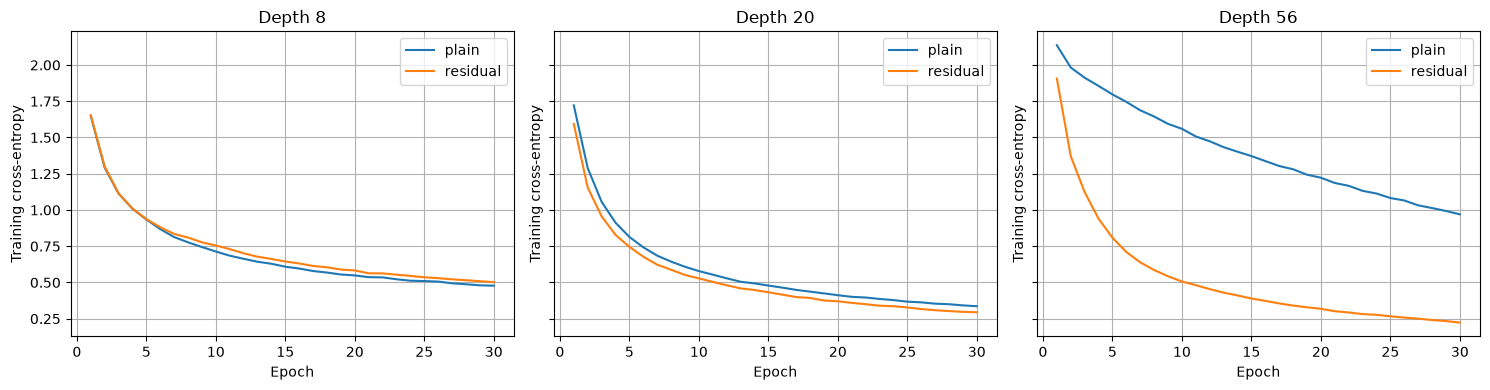

| network | failed | final train loss | best validation accuracy (%) |
| --- | --- | --- | --- |
| plain_8 | False | 0.477919 | 81.4 |
| residual_8 | False | 0.502166 | 79.2 |
| plain_20 | False | 0.336238 | 85.52 |
| residual_20 | False | 0.294515 | 86.16 |
| plain_56 | False | 0.970034 | 65.12 |
| residual_56 | False | 0.223019 | 86.82 |

In [ ]:
depth_runs = {}
for depth in [8, 20, 56]:
    for residual in [False, True]:
        label = f"{'residual' if residual else 'plain'}_{depth}"
        depth_runs[label] = fit_run(
            f"task3b_{label}", lambda d=depth, r=residual: CIFARNet(d, r),
            "Momentum", .03, EPOCHS["depth"], weight_decay=1e-4, augment=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, depth in zip(axes, [8, 20, 56]):
    for family in ["plain", "residual"]:
        history = depth_runs[f"{family}_{depth}"]["history"]
        ax.plot([h["epoch"] for h in history], [h["train_loss"] for h in history], label=family)
    ax.set(title=f"Depth {depth}", xlabel="Epoch", ylabel="Training cross-entropy"); ax.legend()
save_figure("task3b_depth_losses")
depth_rows = []
for label, result in depth_runs.items():
    if result["history"]:
        depth_rows.append({"network": label, "failed": result["failed"],
                           "final train loss": result["history"][-1]["train_loss"],
                           "best validation accuracy (%)": 100 * result["best_val_acc"]})
table(depth_rows)


**Discussion.** At depth 8 both families train similarly (plain slightly better: 0.48 vs 0.50 loss, 81.4% vs 79.2%). At depth 20 residual is slightly ahead. At depth 56 the plain net **degrades**: its training loss (0.97) is far higher than plain-20 (0.34), even though it has more capacity, and validation drops to 65.1%. This is an optimization problem, not overfitting. The residual-56 net has the lowest loss of all (0.22) and the best validation (86.8%). The identity path lets gradients reach early layers directly, and blocks only need to learn small corrections, so the benefit of shortcuts grows with depth.

## Task 4: Best CNN ≤ 500k parameters, ≤ 20 epochs
Reference: ResNet-20 (269,722 params), flip+crop, weight decay $5\times10^{-4}$, momentum SGD. One-factor ablations: no shortcut, no augmentation, no weight decay. Selection by validation; test evaluated once.


task4_reference: using completed run (20 epochs)


task4_no_shortcut: using completed run (20 epochs)


task4_no_augmentation: using completed run (20 epochs)


task4_no_weight_decay: using completed run (20 epochs)


| candidate | parameters | epochs completed | selected epoch | validation accuracy (%) | delta vs reference (pp) |
| --- | --- | --- | --- | --- | --- |
| reference | 269722 | 20 | 20 | 83.26 | 0 |
| no_shortcut | 269722 | 20 | 20 | 81.64 | -1.62 |
| no_augmentation | 269722 | 20 | 11 | 79.82 | -3.44 |
| no_weight_decay | 269722 | 20 | 19 | 84.52 | 1.26 |

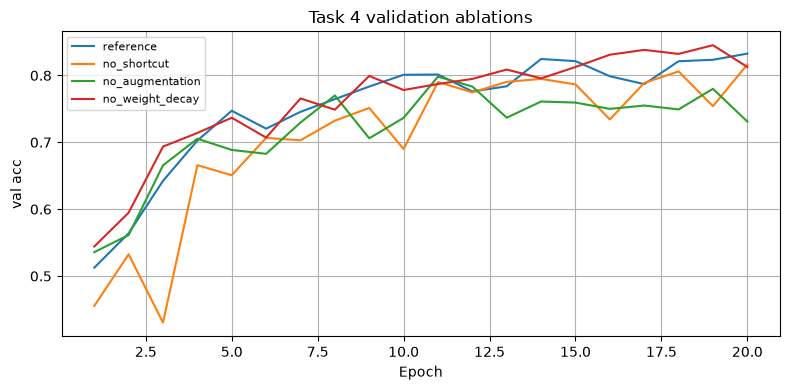

Frozen validation-selected choice: no_weight_decay


In [ ]:
task4_candidates = {
    "reference": dict(residual=True, augment=True, weight_decay=5e-4),
    "no_shortcut": dict(residual=False, augment=True, weight_decay=5e-4),
    "no_augmentation": dict(residual=True, augment=False, weight_decay=5e-4),
    "no_weight_decay": dict(residual=True, augment=True, weight_decay=0.),
}
task4_runs = {}
if RUN_TASK4:
    assert EPOCHS["final"] <= 20
    for label, options in task4_candidates.items():
        factory = lambda r=options["residual"]: CIFARNet(20, r)
        assert parameter_count(factory()) <= 500_000
        task4_runs[label] = fit_run(
            f"task4_{label}", factory, "Momentum", .03, EPOCHS["final"],
            augment=options["augment"], weight_decay=options["weight_decay"])
    successful = {k: v for k, v in task4_runs.items() if not v["failed"]}
    assert successful, "No successful final candidates"
    final_choice = max(successful, key=lambda k: successful[k]["best_val_acc"])
    reference_score = task4_runs["reference"]["best_val_acc"]
    table([{"candidate": k, "parameters": parameter_count(CIFARNet(20, task4_candidates[k]["residual"])),
            "epochs completed": v["completed_epochs"], "selected epoch": v["best_epoch"],
            "validation accuracy (%)": 100 * v["best_val_acc"],
            "delta vs reference (pp)": 100 * (v["best_val_acc"] - reference_score)}
           for k, v in task4_runs.items()])
    plot_histories(task4_runs, "val_acc", "Task 4 validation ablations", "task4_ablations")
    print("Frozen validation-selected choice:", final_choice)
else:
    print("Task 4 is optional. Set RUN_TASK4=True to run its validation experiments.")


In [ ]:
def evaluate_final_test_once(choice, result, candidate_options):
    assert MODE == "full", "Test evaluation is forbidden in smoke mode"
    assert not result["failed"] and result["completed_epochs"] <= 20
    checkpoint_path = Path(result["checkpoint"])
    checkpoint_hash = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()
    receipt_path = OUT / "FINAL_TEST_RECEIPT.json"
    if receipt_path.exists():
        receipt = json.loads(receipt_path.read_text(encoding="utf-8"))
        if receipt.get("status") != "completed":
            raise RuntimeError("A test evaluation was already started. Inspect the receipt; do not rerun test tuning.")
        print("Saved test receipt (no new test evaluation):")
        table([{"metric": k, "value": v} for k, v in receipt.items() if k != "checkpoint_sha256"])
        if receipt["checkpoint_sha256"] != checkpoint_hash:
            print("Receipt belongs to an earlier frozen checkpoint; this new checkpoint was NOT tested.")
        return receipt

    final_model = CIFARNet(20, candidate_options["residual"]).to(DEVICE)
    assert parameter_count(final_model) <= 500_000
    saved = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
    assert saved["config"]["mode"] == "full" and saved["config"]["requested_epochs"] <= 20
    final_model.load_state_dict(saved["state_dict"])
    # This is the ONLY construction of the test dataset anywhere in this notebook.
    test_dataset = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=make_transform())
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    receipt = dict(status="started", choice=choice, checkpoint_sha256=checkpoint_hash,
                   selected_epoch=result["best_epoch"], parameters=parameter_count(final_model))
    # Exclusive creation also prevents two notebook processes from starting the test together.
    with receipt_path.open("x", encoding="utf-8") as stream:
        json.dump(receipt, stream, indent=2)
    metrics = evaluate(final_model, test_loader)
    receipt.update(status="completed", test_accuracy=metrics["acc"], test_loss=metrics["loss"],
                   test_examples=len(test_dataset))
    receipt_path.write_text(json.dumps(receipt, indent=2), encoding="utf-8")
    table([{"metric": k, "value": v} for k, v in receipt.items() if k != "checkpoint_sha256"])
    return receipt


if RUN_TASK4 and ALLOW_FINAL_TEST:
    final_test_result = evaluate_final_test_once(final_choice, task4_runs[final_choice],
                                                task4_candidates[final_choice])
else:
    print("Final test is locked. Finish validation selection before enabling ALLOW_FINAL_TEST.")


| Metric | Value |
| --- | --- |
| Selected model | no_weight_decay |
| Parameters | 269,722 |
| Selected epoch | 19 |
| Test examples | 10,000 |
| Test accuracy | 84.18% |
| Test cross-entropy | 0.4883 |

**Discussion.** Removing augmentation hurts most (−3.4 pp, and it peaks at epoch 11, then overfits) and removing shortcuts costs (−1.6 pp) even at depth 20. Removing weight decay improved validation by (+1.3 pp) within 20 epochs with augmentation, the model is not overfitting much and extra regularization slows fitting. The selected model (ResNet-20, augmentation, no weight decay, epoch 19) scored **84.18%** test accuracy (loss 0.488), close to its 84.52% validation score, so validation-based selection was not noticeably optimistic.


## Acknowledgement of AI tool use
OpenAI Codex was used to help with implementation and to run the experiments. I reviewed and understand all of the code and the discussions.
